# Task 5: Charts for BERT
We draw three charts for the report:
- the learning curves of BERT
- the three BERT settings
- all four models on the test data
The numbers come from the files that we saved before.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
HAM = '#2a78d6'
SPAM = '#eb6834'
os.makedirs('../report', exist_ok=True)
hist = pd.read_csv('../data/bert_history.csv')
variants = pd.read_csv('../data/bert_variants.csv')
comp = pd.read_csv('../data/model_comparison_final.csv')
print(hist)
print()
print(variants)
print()
print(comp)

   epoch  accuracy    loss  val_accuracy  val_loss
0      1    0.9457  0.1439        0.9903    0.0446
1      2    0.9945  0.0265        0.9903    0.0437
2      3    0.9963  0.0142        0.9890    0.0506
3      4    0.9982  0.0064        0.9878    0.0467
4      5    0.9991  0.0030        0.9890    0.0631

                   model  parameters  epochs  best_epoch  precision  recall  \
0        BERT lr 0.00002   109483778       4           1       98.9    93.0   
1        BERT lr 0.00005   109483778       5           2       96.9    94.0   
2  DistilBERT lr 0.00002    66955010       6           3       98.9    93.0   

     f1  
0  95.9  
1  95.4  
2  95.9  

                 model  accuracy  precision  recall    f1  false_alarms  \
0          Naive Bayes      98.9      100.0    91.2  95.4             0   
1  Logistic Regression      99.1       97.5    95.2  96.4             3   
2                 LSTM      98.9       95.2    96.0  95.6             6   
3                 BERT      99.0   

## 1. Learning curves of BERT
We draw the loss and the accuracy after each epoch, on the train part and on the validation part.
The dashed line shows the best epoch (the lowest validation loss).
After this epoch, the train loss keeps going down but the validation loss goes up.
This is overfitting.

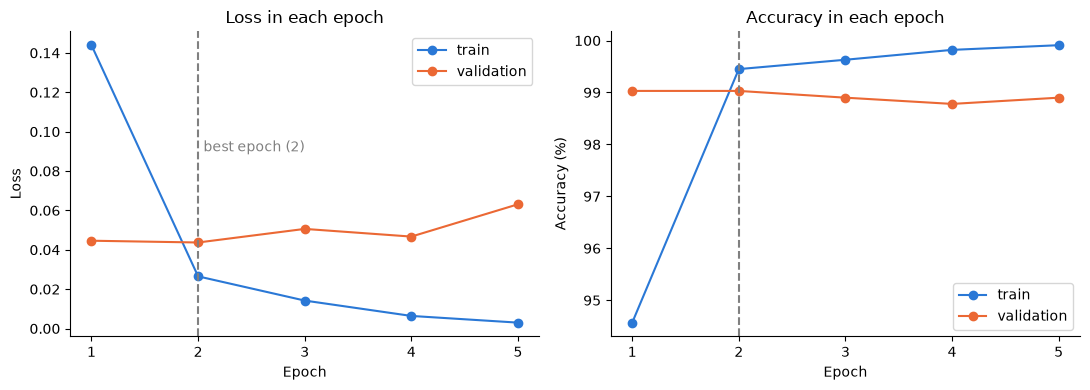

In [2]:
best = int(hist.loc[hist['val_loss'].idxmin(), 'epoch'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.plot(hist['epoch'], hist['loss'], marker='o', color=HAM, label='train')
ax.plot(hist['epoch'], hist['val_loss'], marker='o', color=SPAM, label='validation')
ax.axvline(best, color='gray', linestyle='--')
ax.text(best + 0.05, 0.09, 'best epoch (' + str(best) + ')', color='gray')
ax.set_xticks(hist['epoch'])
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Loss in each epoch')
ax.legend(loc='upper right')
ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
ax.plot(hist['epoch'], 100 * hist['accuracy'], marker='o', color=HAM, label='train')
ax.plot(hist['epoch'], 100 * hist['val_accuracy'], marker='o', color=SPAM, label='validation')
ax.axvline(best, color='gray', linestyle='--')
ax.set_xticks(hist['epoch'])
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Accuracy in each epoch')
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../report/chart8_bert_learning.png', dpi=150)
plt.show()

## 2. The three BERT settings
We draw precision and recall of the three settings on the validation data.
Above each setting we write its F1.
The vertical axis starts at 90, so the small differences are easy to see.

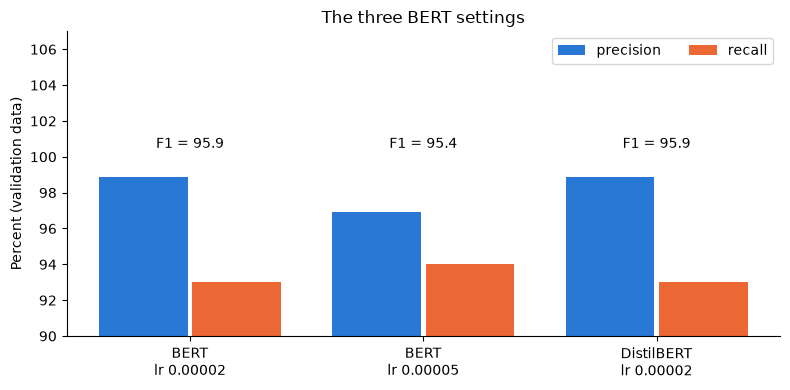

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(variants))
ax.bar([i - 0.2 for i in x], variants['precision'], width=0.38,
       color=HAM, label='precision')
ax.bar([i + 0.2 for i in x], variants['recall'], width=0.38,
       color=SPAM, label='recall')
for i, f in enumerate(variants['f1']):
    ax.text(i, 100.5, 'F1 = ' + str(f), ha='center')
ax.set_xticks(list(x))
ax.set_xticklabels(['BERT\nlr 0.00002', 'BERT\nlr 0.00005',
                    'DistilBERT\nlr 0.00002'])
ax.set_ylim(90, 107)
ax.set_ylabel('Percent (validation data)')
ax.set_title('The three BERT settings')
ax.legend(loc='upper right', ncol=2)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../report/chart9_bert_variants.png', dpi=150)
plt.show()

## 3. All four models on the test data
Left: precision and recall of each model, with its F1 above it.
Right: the two kinds of mistakes.
A false alarm is a normal message called spam. A missed spam is a spam message called normal.
All models were tested on the same 1,026 messages.

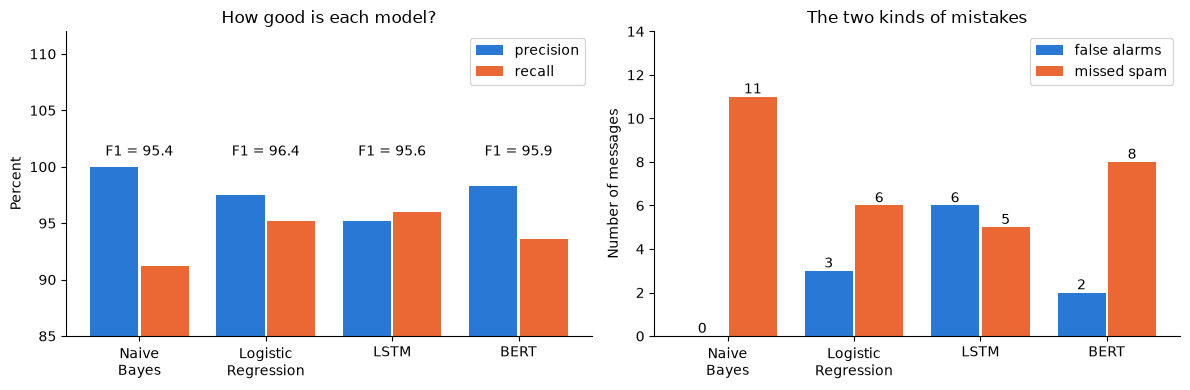

In [4]:
models = comp[comp['model'] != 'Always say ham']
names = ['Naive\nBayes', 'Logistic\nRegression', 'LSTM', 'BERT']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = range(len(models))

ax = axes[0]
ax.bar([i - 0.2 for i in x], models['precision'], width=0.38,
       color=HAM, label='precision')
ax.bar([i + 0.2 for i in x], models['recall'], width=0.38,
       color=SPAM, label='recall')
for i, f in enumerate(models['f1']):
    ax.text(i, 101, 'F1 = ' + str(f), ha='center')
ax.set_xticks(list(x))
ax.set_xticklabels(names)
ax.set_ylim(85, 112)
ax.set_ylabel('Percent')
ax.set_title('How good is each model?')
ax.legend(loc='upper right')
ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
ax.bar([i - 0.2 for i in x], models['false_alarms'], width=0.38,
       color=HAM, label='false alarms')
ax.bar([i + 0.2 for i in x], models['missed'], width=0.38,
       color=SPAM, label='missed spam')
for i, v in enumerate(models['false_alarms']):
    ax.text(i - 0.2, v + 0.15, str(v), ha='center')
for i, v in enumerate(models['missed']):
    ax.text(i + 0.2, v + 0.15, str(v), ha='center')
ax.set_xticks(list(x))
ax.set_xticklabels(names)
ax.set_ylim(0, 14)
ax.set_ylabel('Number of messages')
ax.set_title('The two kinds of mistakes')
ax.legend(loc='upper right')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../report/chart10_all_models.png', dpi=150)
plt.show()